**Name**: Ryan Dyson Darmawan

**SID**: 57883349

# Portfolio Analysis

Mean-variance CAPM analysis of a $100 million fund invested in six U.S. common stocks selected from WRDS, with the one-month t-bills as the risk-free asset.

**Fetching Data**

You need a WRDS subscription and credentials to run this notebook. Run `python fetch_data.py` to get the data. You will be prompted to input your WRDS credentials. Credentials will be saved to an `.env` file. 

**Method** 

Every statistic below is computed from monthly observations and then annualized. 
- Expected returns $E(r_i)$ are annualized with $\times 12$
- Standard deviations $\sigma_i \times \sqrt{12}$, so all numbers are directly comparable. 
- Sharpe ratios are computed on annualized numbers using the annualized average T-bill rate. 
- Optimization uses `scipy.optimize.minimize` (SLSQP), which handles the nonlinear variance objective and equality constraints directly.

**Setup**

Lets setup the directories and libraries that we'll be using in this notebook.

In [36]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from openpyxl import load_workbook
from openpyxl.styles import Font

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
STOCK_FILE = DATA_DIR / "crsp_monthly.csv"
RF_FILE = DATA_DIR / "rf_monthly.csv"

OUTPUT_DIR.mkdir(exist_ok=True)

ALLOW_SHORT = False
MONTHS_PER_YEAR = 12

## 1. Data Ingestion

**Asset selection.** 

Six U.S.-listed common stocks covering more than three industries, each with a complete 60-month return history (Jan 2020 – Dec 2024):

| Ticker | Industry |
|--------|----------|
| MSFT | Technology (software)| 
| NVDA | Technology (semiconductors) |
| JPM | Financials |
| XOM | Energy |
| WMT | Consumer staples |
| JNJ | Healthcare |

**Why these stocks?**

I chose large, liquid S&P 500 components whose monthly observation are complete. All six are US-incorporated, exchange-listed equities. By choosing six distinc industries with very different return drivers, we can diversify our portfolio, driving unsystemic risk down. This is important when we construct a mean-variance portfolio as we try to minimize the portfolio variance. 
- NVDA (Nvidia) and MSFT (Microsoft) are high-growth technology names that dominated 2023-2024.
- JNJ (Johnson and Johnsons) and WMT (Walmart) are defensive, low-beta holdings that held up in the 2020 crash and 2022 drawdown. XOM (Exxon Mobil) adds an inflation-sensitive, cyclical exposure with low correlation to tech. 
- JPM (JP Morgan) provides exposure to interest rates and credit cycles. 
Theoretically, mixing growth, defensive, and cyclical assets keeps correlations low, which should push the efficient frontier outward and give the optimizer more room to build genuinely different portfolios.

**Risk-free rate**

 one-month U.S. Treasury bill rate (January 2020 – December 2024) is used as the risk-free rate. We converted from percent to a decimal monthly rate by `fetch_data.py` and saved to `data/rf_monthly.csv`.

**Data processing**

The cell below loads both files, removes duplicated rows (CRSP imports occasionally contain them), pivots to a wide returns table (months × tickers), and inner-joins the T-bill series so every month has all assets plus the risk-free rate.

In [37]:
def load_stock_data(path):
  stocks = pd.read_csv(path, parse_dates=["MthCalDt"])
  stocks = stocks.drop_duplicates(subset=["PERMNO", "MthCalDt"], keep="first")
  return stocks.pivot(index="MthCalDt", columns="Ticker", values="MthRet").sort_index()

def load_rf_data(path):
  if not path.exists():
    raise FileNotFoundError(
      "data/rf_monthly.csv is missing - run `python fetch_data.py` first. "
    )
  rf = pd.read_csv(path, parse_dates=["MthCalDt"])
  return rf.set_index("MthCalDt").sort_index()["Rf"]

stock_returns = load_stock_data(STOCK_FILE)
rf = load_rf_data(RF_FILE)

data = stock_returns.join(rf.rename("Rf"), how="inner")

tickers = [t for t in data.columns if t != "Rf"]
R = data[tickers]
n = len(tickers)

**Performance statistics of the six assets**

For each asset:
- **Annualized mean return**: $\bar{r}_{\text{ann}} = 12 \cdot \bar{r}_{\text{monthly}}$
- **Annualized standard deviation**: $\sigma_{\text{ann}} = \sigma_{\text{monthly}} \cdot \sqrt{12}$
- **Sharpe ratio**: $SR = \dfrac{\bar{r}_{\text{ann}} - \bar{r}_{f,\text{ann}}}{\sigma_{\text{ann}}}$, using the mean of the monthly T-bill rates, annualized the same way.

In [38]:
ann_mean = R.mean() * MONTHS_PER_YEAR
ann_vol = R.std() * np.sqrt(MONTHS_PER_YEAR)
ann_rf = rf.mean() * MONTHS_PER_YEAR

asset_stats = pd.DataFrame({
  "Annualized mean return": ann_mean,
  "Annualized std. deviation": ann_vol,
  "Sharpe ratio": (ann_mean - ann_rf) / ann_vol,
})

asset_stats.round(4)

,Annualized mean return,Annualized std. deviation,Sharpe ratio
JNJ,0.0408,0.1738,0.0987
JPM,0.1763,0.2779,0.5493
MSFT,0.2315,0.2241,0.9273
NVDA,0.7623,0.4987,1.4813
WMT,0.1999,0.1950,0.9040
XOM,0.1925,0.3421,0.4935


## 2. Constructing the portfolio

**Equally weighted portfolio**

Lets construct and equally weighted portfolio, i.e. each asset has the same weighting at 1/6 of the portfolio's capital. 
- The portfolio's monthly return is the weighted sum of the asset returns, so its expected return and variance follow directly from the monthly means and the covariance matrix. 
- The portfolio mean over the sample is computed both ways below (statistically from mean/covariance, and empirically from realized returns) as a cross-check of the matrix algebra.

In [39]:
mu_monthly = R.mean().to_numpy()
cov_monthly = R.cov().to_numpy()
rf_mean_monthly = float(rf.mean())

def portfolio_return(w):
  return float(np.dot(w, mu_monthly))

def portfolio_variance(w):
  w = np.asarray(w)
  return float(w @ cov_monthly @ w)

def portfolio_std(w):
  return np.sqrt(portfolio_variance(w))

def portfolio_stats(w, label=""):
  ret_m, sd_m = portfolio_return(w), portfolio_std(w)
  stats = {
    "Monthly expected return": ret_m,
    "Monthly std. deviation": sd_m,
    "Annualized expected return": ret_m * MONTHS_PER_YEAR,
    "Annualized std. deviation": sd_m * np.sqrt(MONTHS_PER_YEAR),
    "Sharpe ratio": (ret_m - rf_mean_monthly) / sd_m,
  }
  return pd.Series(stats, name=label)

w_ew = np.repeat(1 / n, n)
ew_weights = pd.Series(w_ew, index=tickers, name="Weight")
ew_stats = portfolio_stats(w_ew, label="Equal-weighted portfolio")

display(ew_weights.round(4).to_frame("Weight"))
display(ew_stats.round(4).to_frame("Value"))

,Weight
JNJ,0.1667
JPM,0.1667
MSFT,0.1667
NVDA,0.1667
WMT,0.1667
XOM,0.1667


,Value
Monthly expected return,0.0223
Monthly std. deviation,0.0536
Annualized expected return,0.2672
Annualized std. deviation,0.1857
Sharpe ratio,0.3787


**Mean-variance portfolio**

The **mean-variance frontier** is the set of assets offering the lowest variance for each attainable expected return. Basically, an optimization problem of the variance:

$$\min \sigma_p^2 = min[\sum_{i=1}^{N} w_i^2 \sigma_i^2 + \sum_{i=1}^{N} \sum_{\substack{j=1 \\ j \neq i}}^{N} w_i w_j \sigma_{ij}]$$

where:

- $\sigma_p^2$ : Portfolio variance or "risk"
- $w_i$ : Weight of asset $i$ in the portfolio
- $\sigma_i^2$ : Variance of asset $i$ 
- $\sigma_{ij}$ : Covariance between asset $i$ and asset $j$
- $N$ : Total number of assets in the portfolio

Mathematically, we can do this by deriving the variance with respect to $w$ and setting it to 0 to find the optimal weights.

**Tangent portfolio**

The **tangency portfolio** lies on the frontier mentioned earlier and has the highest Sharpe ratio. To find it, maximise the Sharpe ratio over the same feasible set. 

$$\max\text{Sharpe Ratio}=\max\frac{E(R_p)-r_f}{\sigma_p}$$

Similarly, we can derive the sharpe ratio with respect to $w$ and set it to 0 to find the optimal weights.

**Capital allocation line (CAL)**

After finding the mean-variance portfolio and tangent portfolio, we can construct the Capital Allocation Line (CAL). 

The cells below define the two optimizations, then sweep target returns across the range of the six assets' means and plot the frontier with the tangency portfolio, the equally weighted portfolio, the individual assets, and the CAL.

In [40]:
bounds = None if ALLOW_SHORT else [(0, 1) for _ in range(n)]
budget = {"type": "eq", "fun": lambda w: np.sum(w) - 1}

def optimize_min_var(target_return):
  result = minimize(
    portfolio_variance,
    x0=np.repeat(1 / n, n),
    method="SLSQP",
    bounds=bounds,
    constraints=[
      budget,
      {"type": "eq", "fun": lambda w: portfolio_return(w) - target_return},
    ],
  )
  return np.asarray(result.x)

def optimize_tangency():
  result = minimize(
    lambda w: -(portfolio_return(w) - rf_mean_monthly) / portfolio_std(w),
    x0=np.repeat(1 / n, n),
    method="SLSQP",
    bounds=bounds,
    constraints=[budget],
  )
  return np.asarray(result.x)

In [41]:
w_tan = optimize_tangency()
w_tan = np.clip(w_tan, 0.0, None)
w_tan = w_tan / w_tan.sum() 

tan_stats = portfolio_stats(w_tan, label="Tangency portfolio")
tangency_weights = pd.Series(w_tan, index=tickers, name="Weight")

display(tangency_weights.round(4).to_frame("Weight"))
display(tan_stats.round(4).to_frame("Value"))

,Weight
JNJ,0.0000
JPM,0.0000
MSFT,0.0000
NVDA,0.4282
WMT,0.3778
XOM,0.1940


,Value
Monthly expected return,0.0366
Monthly std. deviation,0.0745
Annualized expected return,0.4393
Annualized std. deviation,0.2582
Sharpe ratio,0.4647


This cell below will plot our mean frontier, CAL, and tangent portfolio using matplotlib.

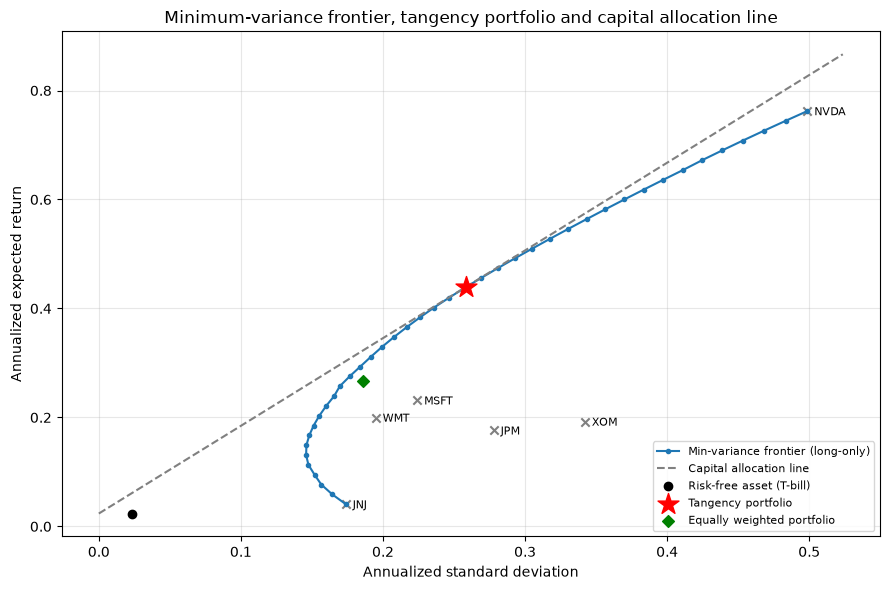

,Monthly expected return,Monthly std. deviation,Annualized expected return,Annualized std. deviation
0,0.0034,0.0502,0.0408,0.1738
1,0.0049,0.0474,0.0588,0.1643
2,0.0064,0.0452,0.0769,0.1566
3,0.0079,0.0438,0.0949,0.1519
4,0.0094,0.0426,0.1129,0.1475
5,0.0109,0.0421,0.1310,0.1459
6,0.0124,0.0422,0.1490,0.1461
7,0.0139,0.0428,0.1671,0.1481
8,0.0154,0.0436,0.1851,0.1512
9,0.0169,0.0448,0.2031,0.1552


In [42]:
rows = []
target_grid = np.linspace(mu_monthly.min(), mu_monthly.max(), 41)
for target in target_grid:
  try:
    w = optimize_min_var(target)
  except RuntimeError:
    continue  
  rows.append({
    "Monthly expected return": target,
    "Monthly std. deviation": portfolio_std(w),
  })

frontier = pd.DataFrame(rows)
frontier["Annualized expected return"] = frontier["Monthly expected return"] * MONTHS_PER_YEAR
frontier["Annualized std. deviation"] = frontier["Monthly std. deviation"] * np.sqrt(MONTHS_PER_YEAR)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(frontier["Annualized std. deviation"], frontier["Annualized expected return"], "-o", ms=3, label="Min-variance frontier (long-only)")

cal_sd = np.linspace(0, max(frontier["Annualized std. deviation"]) * 1.05, 50)
cal_ret = ann_rf + (tan_stats["Annualized expected return"] - ann_rf) / tan_stats["Annualized std. deviation"] * cal_sd
ax.plot(cal_sd, cal_ret, "--", color="grey", label="Capital allocation line")
ax.scatter([ann_rf], [ann_rf], marker="o", color="black", zorder=5, label="Risk-free asset (T-bill)")

ax.scatter(tan_stats["Annualized std. deviation"], tan_stats["Annualized expected return"], marker="*", s=250, color="red", zorder=6, label="Tangency portfolio")
ax.scatter(ew_stats["Annualized std. deviation"], ew_stats["Annualized expected return"], marker="D", color="green", zorder=6, label="Equally weighted portfolio")

for i, t in enumerate(tickers):
  ax.scatter(ann_vol.iloc[i], ann_mean.iloc[i], marker="x", color="grey")
  ax.annotate(t, (ann_vol.iloc[i], ann_mean.iloc[i]), textcoords="offset points", xytext=(5, -3), fontsize=8)

ax.set_xlabel("Annualized standard deviation")
ax.set_ylabel("Annualized expected return")
ax.set_title("Minimum-variance frontier, tangency portfolio and capital allocation line")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "frontier.png", dpi=150)
plt.show()

frontier.round(4)

## 3. Is the equally weighted portfolio efficient?

Using the domination rule, investors are risk-averse. This means that portfolios with the same risk $\sigma$, but with different expected returns $E(r)$, the portfolio with the higher expected return will dominate the lower one. These dominating portfolios are efficient portfolios. From this we can observe what is known as an efficient frontier. I.e. the part of the mean-variance frontier that lies above the nose of the curve. 

To test, construct the minimum-variance portfolio with **the same expected return as the equally weighted portfolio**. If that optimized portfolio has a strictly lower standard deviation (equivalently, a higher Sharpe ratio), the equal-weight policy is not efficient, and the optimized weights are the efficient replacement delivering the same expected return.

In [43]:
w_eff = optimize_min_var(ew_stats["Monthly expected return"])
w_eff = np.clip(w_eff, 0.0, None)
w_eff = w_eff / w_eff.sum()

eff_stats = portfolio_stats(w_eff, label="Efficient portfolio (same expected return)")
efficient_weights = pd.Series(w_eff, index=tickers, name="Weight")

display(efficient_weights.round(4).to_frame("Weight"))

comparison = pd.concat([ew_stats, eff_stats], axis=1).T
display(comparison.round(4))

sd_gap = ew_stats["Monthly std. deviation"] - eff_stats["Monthly std. deviation"]

,Weight
JNJ,0.1887
JPM,0.0000
MSFT,0.1602
NVDA,0.1660
WMT,0.3401
XOM,0.1450


,Monthly expected return,Monthly std. deviation,Annualized expected return,Annualized std. deviation,Sharpe ratio
Equal-weighted portfolio,0.0223,0.0536,0.2672,0.1857,0.3787
Efficient portfolio (same expected return),0.0223,0.0500,0.2672,0.1733,0.4057


## 4. Efficient allocation meeting the 1% monthly floor return

With a risk-free asset available, every efficient *complete* portfolio is a mix of the **risk-free asset and the tangency portfolio** sitting on the capital allocation line. To hit the client's floor of **1% per month**, I solve for the tangency weight $y$ such that

$$r_f + y\,(r_{\tan} - r_f) = 1\% \quad \Longleftrightarrow \quad y = \frac{1\% - r_f}{r_{\tan} - r_f},$$

the remainder $1 - y$ is invested at the T-bill rate, and the standard deviation scales to $\sigma = y \cdot \sigma_{\tan}$. If $y > 1$ the floor requires borrowing at the T-bill rate (a levered position in the tangency portfolio). Dollar amounts for the $100 million fund are shown alongside the weights.

In [ ]:
floor_monthly = 0.01  # client's floor: 1% per month
FUND_SIZE = 100_000_000

y_tan = (floor_monthly - rf_mean_monthly) / (tan_stats["Monthly expected return"] - rf_mean_monthly)
w_rf_complete = 1 - y_tan
floor_sd_monthly = y_tan * tan_stats["Monthly std. deviation"]

floor_allocation = pd.DataFrame({
  "Weight": [w_rf_complete, y_tan],
  "$ amount": [w_rf_complete * FUND_SIZE, y_tan * FUND_SIZE],
}, index=["Risk-free asset (T-bill)", "Tangency portfolio"])

floor_stats = pd.Series({
  "Monthly expected return": floor_monthly,
  "Monthly std. deviation": floor_sd_monthly,
  "Annualized expected return": floor_monthly * MONTHS_PER_YEAR,
  "Annualized std. deviation": floor_sd_monthly * np.sqrt(MONTHS_PER_YEAR),
})

print("Allocation to achieve the 1% monthly floor:")
display(floor_allocation.round(3))
print("Statistics of the floor portfolio:")
display(floor_stats.round(4).to_frame("Value"))
if y_tan > 1:
  print("Note: weight > 100% in the tangency portfolio means borrowing at the T-bill rate (leverage).")


## Export all results to Excel

The submission workbook `output/EF3320_Assignment1_Challenge.xlsx` is built to the assignment brief: *"Upload your completed Excel file to Canvas, including all detailed calculations and work"* and *"Highlight your final answers where appropriate"*.

Sheets, one per task:

- **Read Me** — overview: data sources, methodology and where each task's answer lives
- **Monthly Returns** — ticker × month return table (Task 1)
- **Risk-Free Rate** — monthly one-month T-bill rates (Task 1)
- **Asset Statistics** — annualized mean return, standard deviation and Sharpe ratio (Task 2)
- **Equal-Weight Portfolio** — policy portfolio weights and statistics (Task 3)
- **Tangency Portfolio** — weights, expected return and standard deviation of the optimal risky portfolio (Task 4)
- **Frontier** — min-variance frontier coordinates with the frontier, tangency portfolio, equal-weight portfolio and CAL plotted in a native Excel chart (Task 4)
- **Efficient vs Equal-Weight** — efficiency test and replacement weights (Task 5)
- **Floor Allocation** — allocation achieving the 1% monthly floor (Task 6)

Formatting: styled headers, auto-sized columns, percent/currency/date number formats, frozen panes on the data sheets, and **final answers highlighted in yellow**.

In [46]:
from openpyxl import Workbook
from openpyxl.chart import Reference, ScatterChart, Series
from openpyxl.chart.marker import Marker
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

EXCEL_FILE = OUTPUT_DIR / "EF3320_Assignment1_Challenge.xlsx"

NAVY = "1F4E78"
HEAD_FILL = PatternFill("solid", fgColor=NAVY)
HEAD_FONT = Font(bold=True, color="FFFFFF")
TITLE_FONT = Font(bold=True, size=14, color=NAVY)
ANSWER_FILL = PatternFill("solid", fgColor="FFF2CC")
THIN = Side(style="thin", color="D9D9D9")
HEAD_BORDER = Border(bottom=Side(style="thin", color="404040"))
PCT, DEC2, USD, DATE = "0.00%", "0.00", "$#,##0", "yyyy-mm-dd"

wb = Workbook()
wb.remove(wb.active)

def new_sheet(name, task):
    ws = wb.create_sheet(name)
    ws["A1"] = f"EF3320 Assignment 1 (Challenge) - {task}"
    ws["A1"].font = TITLE_FONT
    return ws

def stat_format(label):
    if "Sharpe" in label:
        return DEC2
    if "return" in label or "deviation" in label:
        return PCT
    return None

def put_table(ws, df, row, col=1, index=True, answers=False, col_formats=None):
    col_formats = col_formats or {}
    headers = ([str(df.index.name or "")] if index else []) + [str(x) for x in df.columns]
    for j, name in enumerate(headers):
        cell = ws.cell(row=row, column=col + j, value=name)
        cell.fill, cell.font, cell.border = HEAD_FILL, HEAD_FONT, HEAD_BORDER
        cell.alignment = Alignment(horizontal="center")
    for i in range(len(df)):
        vals = ([df.index[i]] if index else []) + list(df.iloc[i].tolist())
        for j, v in enumerate(vals):
            if isinstance(v, pd.Timestamp):
                v = v.to_pydatetime()
            cell = ws.cell(row=row + 1 + i, column=col + j, value=v)
            if isinstance(v, float):
                cell.number_format = col_formats.get(j, "General")
            if answers:
                cell.fill = ANSWER_FILL
    autosize(ws, row, col, headers, len(df))
    return row + len(df) + 2

def put_stats(ws, series, row, col=1, answers=True):
    df = series.to_frame("Value")
    headers = [str(df.index.name or "")] + ["Value"]
    for j, name in enumerate(headers):
        cell = ws.cell(row=row, column=col + j, value=name)
        cell.fill, cell.font, cell.border = HEAD_FILL, HEAD_FONT, HEAD_BORDER
    for i in range(len(df)):
        label, v = str(df.index[i]), float(df.iloc[i, 0])
        cell = ws.cell(row=row + 1 + i, column=col, value=label)
        val = ws.cell(row=row + 1 + i, column=col + 1, value=v)
        fmt = stat_format(label)
        if fmt:
            val.number_format = fmt
        if answers:
            cell.fill = val.fill = ANSWER_FILL
    autosize(ws, row, col, headers, len(df))
    return row + len(df) + 2

def autosize(ws, header_row, col, headers, n_rows):
    for j, name in enumerate(headers):
        letter = get_column_letter(col + j)
        width = len(name)
        for i in range(n_rows + 1):
            v = ws.cell(row=header_row + i, column=col + j).value
            if v is None:
                continue
            width = max(width, len(f"{v:,.2f}") if isinstance(v, float) else len(str(v)))
        ws.column_dimensions[letter].width = min(width + 2, 30)

ws = new_sheet("Read Me", "Overview")
notes = [
    "Fund: $100,000,000 - six US-listed common stocks (CRSP monthly returns via WRDS)",
    "Sample: January 2020 - December 2024 (60 monthly observations per asset)",
    "Risk-free asset: one-month US T-bill (Fama-French Data Library), average of monthly rates",
    "Method: statistics computed monthly, annualized (mean x12, std dev x sqrt(12));",
    "  Sharpe ratio = (annualized mean - annualized risk-free rate) / annualized std dev;",
    "  optimization via scipy SLSQP, long-only (0 <= w <= 1) by default",
    "Sources: WRDS (crsp.msf_v2, crsp.stocknames) and Fama-French Data Library - see fetch_data.py",
    "FINAL ANSWERS ARE HIGHLIGHTED IN YELLOW ON EVERY SHEET",
]
for k, line in enumerate(notes):
    ws.cell(row=3 + k, column=1, value=line)
tasks = [
    ("Task 1", "Monthly Returns, Risk-Free Rate", "ticker symbols and monthly returns"),
    ("Task 2", "Asset Statistics", "annualized mean, std dev, Sharpe ratio per asset"),
    ("Task 3", "Equal-Weight Portfolio", "current policy: 1/6 in each asset"),
    ("Task 4", "Tangency Portfolio, Frontier", "optimal risky portfolio + Excel frontier chart"),
    ("Task 5", "Efficient vs Equal-Weight", "efficiency test and efficient replacement weights"),
    ("Task 6", "Floor Allocation", "allocation achieving the 1% monthly floor"),
]
ws.cell(row=13, column=1, value="Task").font = HEAD_FONT
ws.cell(row=13, column=1).fill = HEAD_FILL
ws.cell(row=13, column=2, value="Sheet(s)").font = HEAD_FONT
ws.cell(row=13, column=2).fill = HEAD_FILL
ws.cell(row=13, column=3, value="Contents").font = HEAD_FONT
ws.cell(row=13, column=3).fill = HEAD_FILL
for k, (task, sheet_names, what) in enumerate(tasks):
    ws.cell(row=14 + k, column=1, value=task)
    ws.cell(row=14 + k, column=2, value=sheet_names)
    ws.cell(row=14 + k, column=3, value=what)
ws.column_dimensions["A"].width = 10
ws.column_dimensions["B"].width = 32
ws.column_dimensions["C"].width = 52

R_out = R.copy()
R_out.index.name = "MthCalDt"
ws = new_sheet("Monthly Returns", "Task 1 - monthly returns by ticker")
put_table(ws, R_out, 3, col_formats={0: DATE, **{j: PCT for j in range(1, n + 1)}})
ws.freeze_panes = "B4"

rf_out = rf.to_frame("T-bill monthly rate")
rf_out.index.name = "MthCalDt"
ws = new_sheet("Risk-Free Rate", "Task 1 - one-month US T-bill rate")
put_table(ws, rf_out, 3, col_formats={0: DATE, 1: PCT})
ws.freeze_panes = "A4"

ws = new_sheet("Asset Statistics", "Task 2 - performance statistics of the six assets")
put_table(ws, asset_stats.round(6), 3, answers=True,
          col_formats={1: PCT, 2: PCT, 3: DEC2})

ws = new_sheet("Equal-Weight Portfolio", "Task 3 - current policy: 1/6 per asset")
end = put_table(ws, ew_weights.round(6).to_frame("Weight"), 3, answers=True, col_formats={1: PCT})
put_stats(ws, ew_stats.round(6), end + 1)

ws = new_sheet("Tangency Portfolio", "Task 4 - optimal risky portfolio (max Sharpe)")
end = put_table(ws, tangency_weights.round(6).to_frame("Weight"), 3, answers=True, col_formats={1: PCT})
put_stats(ws, tan_stats.round(6), end + 1)

ws = new_sheet("Frontier", "Task 4 - minimum-variance frontier (chart to the right)")
frontier_out = frontier[["Annualized std. deviation", "Annualized expected return"]].round(6)
head_row = 3
end = put_table(ws, frontier_out, head_row, index=False,
                col_formats={0: PCT, 1: PCT})
first, last = head_row + 1, head_row + len(frontier_out)

points = pd.DataFrame({
    "Annualized std. deviation": [tan_stats["Annualized std. deviation"],
                                  ew_stats["Annualized std. deviation"],
                                  float(ann_rf), 0.0],
    "Annualized expected return": [tan_stats["Annualized expected return"],
                                   ew_stats["Annualized expected return"],
                                   float(ann_rf), float(ann_rf)],
}, index=["Tangency portfolio", "Equally weighted portfolio",
          "Risk-free asset (T-bill)", "CAL start (0 risk)"])
prow = end + 2
put_table(ws, points.round(6), prow, answers=True, col_formats={1: PCT, 2: PCT})

chart = ScatterChart()
chart.title = "Minimum-variance frontier (long-only)"
chart.x_axis.title = "Annualized std. deviation"
chart.y_axis.title = "Annualized expected return"
chart.height, chart.width = 11, 17
s = Series(Reference(ws, min_col=2, min_row=first, max_row=last),
           Reference(ws, min_col=1, min_row=first, max_row=last),
           title="Min-variance frontier")
s.marker = Marker(symbol="circle", size=5)
s.graphicalProperties.line.noFill = True
chart.series.append(s)
labels = [("Tangency portfolio", "star", 10, True),
          ("Equally weighted portfolio", "diamond", 8, True),
          ("Risk-free asset (T-bill)", "circle", 7, True),
          ("CAL start (0 risk)", "none", 6, False)]
for k, (label, sym, size, point) in enumerate(labels):
    r = prow + 2 + k
    s = Series(Reference(ws, min_col=3, min_row=r, max_row=r),
               Reference(ws, min_col=2, min_row=r, max_row=r),
               title=label)
    s.marker = Marker(symbol=sym, size=size)
    if point:
        s.graphicalProperties.line.noFill = True
    chart.series.append(s)
ws.add_chart(chart, "F3")

eff_table = pd.concat([
    ew_weights.rename("Equal weight"), efficient_weights.rename("Efficient weight")], axis=1)
eff_comparison = pd.concat([ew_stats, eff_stats], axis=1)

ws = new_sheet("Efficient vs Equal-Weight", "Task 5 - efficiency test at the equal-weight return")
end = put_table(ws, eff_table.round(6), 3, answers=True, col_formats={1: PCT, 2: PCT})
end = put_stats(ws, ew_stats.round(6), end + 1, answers=False)
end = put_stats(ws, eff_stats.round(6), end, answers=False)
gap = ew_stats["Monthly std. deviation"] - eff_stats["Monthly std. deviation"]
verdict = ("Equally weighted portfolio is NOT efficient: the efficient portfolio with the same "
           f"expected return cuts the monthly std. deviation by {gap:.4%}."
           if gap > 1e-4 else "Equally weighted portfolio is (numerically) efficient for its return level.")
cell = ws.cell(row=end + 1, column=1, value=verdict)
cell.font = Font(bold=True, italic=True)
cell.fill = ANSWER_FILL

ws = new_sheet("Floor Allocation", "Task 6 - allocation achieving the 1% monthly floor")
end = put_table(ws, floor_allocation.round(6), 3, answers=True, col_formats={1: PCT, 2: USD})
put_stats(ws, floor_stats.round(6), end + 1)
if y_tan > 1:
    note = ws.cell(row=end + 10, column=1,
                   value="Note: tangency weight > 100% = borrowing at the T-bill rate (leverage).")
    note.font = Font(italic=True)

wb.save(EXCEL_FILE)
print(f"Wrote {EXCEL_FILE.resolve()}")


Wrote D:\Schoolwork\Y4A\Portfolio Analysis\Assignment 1\output\EF3320_Assignment1_Challenge.xlsx
